# 8. An autoencoder on MetroPT

Notebook 4 learned what normal operation looks like with a density model. This
notebook does the same job with the other model from lecture block 1: an
autoencoder.

The idea is different but the output is the same kind of thing. A small network is
trained to squeeze the seven sensor readings down to three numbers and then rebuild
the seven from those three. It can only learn to do that well for the kind of
readings it was trained on. A reading from a leaking compressor is unlike anything
in February and March, so the network rebuilds it badly. **The score is how badly**:
the reconstruction error.

Same data, same training period and same scaling as notebook 4, so the two detectors
can be compared directly. Like notebook 7, we compare them at the same false alarm
budget, not each at its own best threshold.

In [1]:
import sys
import zipfile

import numpy as np
import pandas as pd
from matplotlib import pyplot as plt
from sklearn.preprocessing import StandardScaler

import keras
from keras import layers

sys.path.insert(0, '..')
from util.evaluation import evaluate

SENSORS = ['TP2', 'TP3', 'H1', 'DV_pressure', 'Reservoirs',
           'Oil_temperature', 'Motor_current']

# Ends at 23:50, the last row of the day (see notebook 6).
FAILURES = [
    ('2020-04-18', '2020-04-18 23:50'),   # F1
    ('2020-05-29', '2020-05-30 23:50'),   # F2
    ('2020-06-05', '2020-06-07 23:50'),   # F3
    ('2020-07-15', '2020-07-15 23:50'),   # F4
]
NAMES = ['F1', 'F2', 'F3', 'F4']

EVAL_FROM = '2020-04-01'
COST_MISSED = 20

## The data

Identical to notebook 4: 10-minute means of the seven analogue sensors, trained on
February and March, scaled with a `StandardScaler` fitted on those two months.

In [2]:
with zipfile.ZipFile('../data/metropt3.zip') as z:
    name = [n for n in z.namelist() if n.endswith('.csv')][0]
    with z.open(name) as f:
        raw = pd.read_csv(f)

raw['timestamp'] = pd.to_datetime(raw['timestamp'])
data = raw.sort_values('timestamp').set_index('timestamp')[SENSORS]
data = data.resample('10min').mean().dropna()

train = data.loc[:'2020-03-31']
scaler = StandardScaler().fit(train)
X_train = scaler.transform(train)
X_all = scaler.transform(data)

print(f'{len(data):,} rows, training on {len(train):,}')

25,521 rows, training on 7,422


## The network

Three layers in, three layers out. Every layer is an ordinary dense layer: each
output is a weighted sum of all its inputs, passed through an activation.

| layer | size | what it does |
|---|---|---|
| input | 7 | the seven scaled sensor readings |
| encoder 1 | 6 | first combination of the sensors |
| encoder 2 | 4 | narrower: the network has to start discarding detail |
| **bottleneck** | **3** | the whole reading summarised in three numbers |
| decoder 1 | 4 | mirror of encoder 2 |
| decoder 2 | 6 | mirror of encoder 1 |
| output | 7 | its attempt at the original seven readings |

The hidden layers use ReLU, which lets the network bend: without it the whole thing
collapses into one linear map, which is just PCA. The bottleneck and output are
linear, because they have to be able to take any value, negative included, like the
scaled readings they stand for.

**Why three in the middle.** Three numbers can only describe seven readings if the
readings are far from independent. The check below says how far.

It is trained to make output equal input, with mean squared error as the loss.

In [3]:
corr = train.corr().round(2)
print('correlation between sensors in February and March\n')
print(corr)

eig = np.linalg.eigvalsh(np.cov(X_train.T))[::-1]
print('\nshare of the variation captured by the first k directions (PCA):')
print(pd.Series(np.cumsum(eig) / eig.sum(), index=range(1, 8)).round(3).to_string())

correlation between sensors in February and March

                  TP2   TP3    H1  DV_pressure  Reservoirs  Oil_temperature  \
TP2              1.00  0.01 -0.97         0.84        0.01             0.56   
TP3              0.01  1.00  0.24        -0.00        1.00             0.35   
H1              -0.97  0.24  1.00        -0.82        0.24            -0.45   
DV_pressure      0.84 -0.00 -0.82         1.00       -0.00             0.54   
Reservoirs       0.01  1.00  0.24        -0.00        1.00             0.35   
Oil_temperature  0.56  0.35 -0.45         0.54        0.35             1.00   
Motor_current    0.77  0.37 -0.65         0.51        0.37             0.59   

                 Motor_current  
TP2                       0.77  
TP3                       0.37  
H1                       -0.65  
DV_pressure               0.51  
Reservoirs                0.37  
Oil_temperature           0.59  
Motor_current             1.00  

share of the variation captured by the first k dire

The seven sensors are far from independent. TP3 and Reservoirs are the same signal
(correlation 1.00), TP2 and H1 mirror each other (-0.97), and DV_pressure and
Motor_current follow TP2. Three directions already describe 93 % of the variation in
February and March, four describe 99 %.

So three numbers are enough to rebuild ordinary operation well, but not quite
enough to copy any input through unchanged. That second part is the point: a network
that could copy everything would rebuild a leak perfectly too. Four would leave
almost no room; two would already lose a third of normal operation (87 %).

In [4]:
def build(bottleneck=3):
    model = keras.Sequential([
        keras.Input(shape=(len(SENSORS),)),
        layers.Dense(6, activation='relu'),
        layers.Dense(4, activation='relu'),
        layers.Dense(bottleneck),                 # linear
        layers.Dense(4, activation='relu'),
        layers.Dense(6, activation='relu'),
        layers.Dense(len(SENSORS)),               # linear
    ])
    model.compile(optimizer='adam', loss='mse')
    return model


build().summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 6)              │            48 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 4)              │            28 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 3)              │            15 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 4)              │            16 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 6)              │            30 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 7)              │            49 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 186 (744.00 B)

 Trainable params: 186 (744.00 B)

 Non-trainable params: 0 (0.00 B)

186 weights in total, against 7 422 training rows of 7 numbers each. There is
no risk of it memorising the training set.

## Training

We hold back the last 20 % of the training period (late March) as validation, to see
whether what it learns carries over to readings it has not seen. 30 passes over the
data (epochs). The loss curve below tells us whether that is enough.

final loss: training 0.087, validation 0.075
validation loss at epoch 5, 10, 20, 30: [0.342, 0.233, 0.097, 0.075]


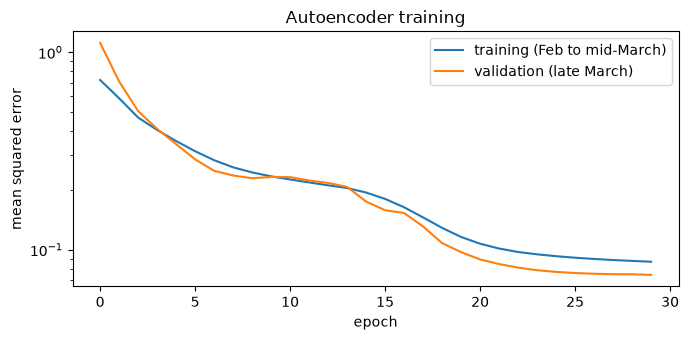

In [5]:
EPOCHS = 30


def train_autoencoder(seed, bottleneck=3):
    keras.utils.set_random_seed(seed)
    model = build(bottleneck)
    history = model.fit(X_train, X_train, epochs=EPOCHS, batch_size=64,
                        validation_split=0.2, shuffle=True, verbose=0)
    return model, history


model, history = train_autoencoder(seed=0)

fig, ax = plt.subplots(figsize=(7, 3.5))
ax.plot(history.history['loss'], label='training (Feb to mid-March)')
ax.plot(history.history['val_loss'], label='validation (late March)')
ax.set_yscale('log')
ax.set_xlabel('epoch')
ax.set_ylabel('mean squared error')
ax.set_title('Autoencoder training')
ax.legend()
plt.tight_layout()

print(f'final loss: training {history.history["loss"][-1]:.3f}, '
      f'validation {history.history["val_loss"][-1]:.3f}')
print('validation loss at epoch 5, 10, 20, 30:',
      [round(history.history['val_loss'][i - 1], 3) for i in (5, 10, 20, 30)])

## The score

For each row: rebuild it, and take the mean squared difference between the seven
scaled readings and the seven rebuilt ones. High means the network could not
reproduce it, so it is unlike February and March.

In [6]:
def reconstruction_error(model):
    rebuilt = model.predict(X_all, batch_size=1024, verbose=0)
    return pd.Series(((X_all - rebuilt) ** 2).mean(axis=1), index=data.index)


scores = reconstruction_error(model)
scores.describe(percentiles=[0.5, 0.9, 0.99]).round(3)

count    25521.000
mean         0.520
std          2.202
min          0.000
50%          0.091
90%          0.349
99%         13.609
max         21.171
dtype: float64

## Does the random start matter?

A network starts from random weights, so two training runs give two slightly
different detectors. Notebook 4 had a bandwidth to check; here the equivalent
question is whether the result depends on the seed. Three seeds, same summary as
notebook 4: how much of each failure scores above the 99th percentile of normal.

In [7]:
in_failure = pd.Series(False, index=data.index)
for start, end in FAILURES:
    in_failure.loc[start:end] = True


def summarise(s):
    normal99 = s[~in_failure].quantile(0.99)
    row = {'99th pct normal': normal99,
           'median in failure': s[in_failure].median()}
    for name, (start, end) in zip(NAMES, FAILURES):
        row[f'{name} above'] = (s[start:end] > normal99).mean()
    return row


runs = {0: scores}
for seed in [1, 2]:
    runs[seed] = reconstruction_error(train_autoencoder(seed)[0])

table = pd.DataFrame({f'seed {k}': summarise(s) for k, s in runs.items()}).T
table.style.format('{:.2f}').format('{:.0%}', subset=[f'{n} above' for n in NAMES])

,99th pct normal,median in failure,F1 above,F2 above,F3 above,F4 above
seed 0,6.53,9.98,99%,14%,83%,0%
seed 1,5.63,8.04,99%,14%,83%,0%
seed 2,6.85,10.25,99%,14%,83%,0%


If the three rows tell the same story (the same failures stand out, roughly the same
share of each), the seed is not where the decision lies, and we use seed 0 from here
on, as we used bandwidth 0.5 in notebook 4.

## Next to the KDE

Both scores on the same axis would be meaningless (one is a negative log density,
the other a squared error), so each gets its own panel.

rank correlation between the two scores: 0.76


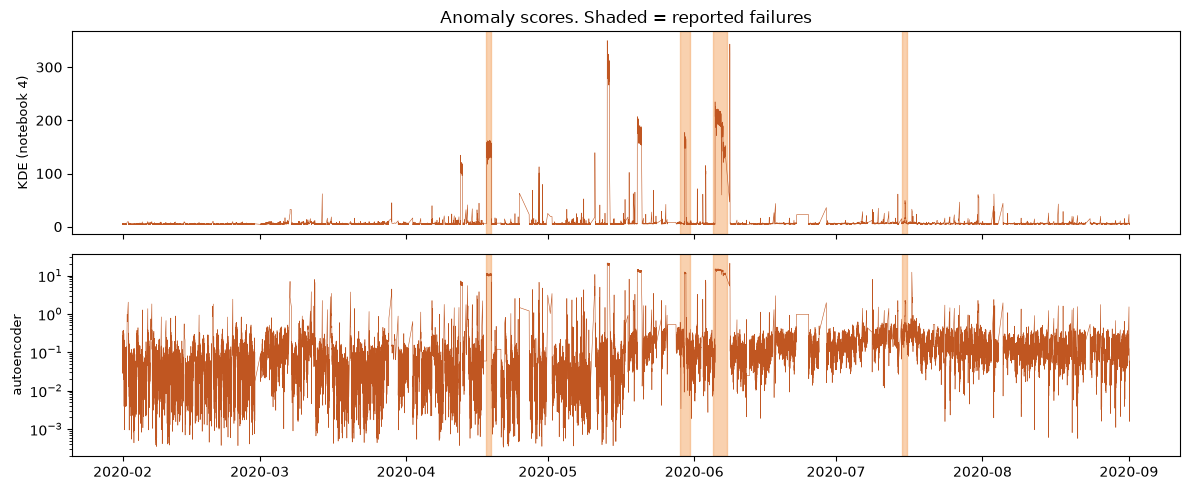

In [8]:
kde = pd.read_csv('../results/metropt_scores.csv', index_col='timestamp',
                  parse_dates=True)['score']

fig, axes = plt.subplots(2, 1, figsize=(12, 5), sharex=True)
for ax, (name, s) in zip(axes, [('KDE (notebook 4)', kde), ('autoencoder', scores)]):
    ax.plot(s.index, s, lw=0.4, color='#c05621')
    ax.set_ylabel(name, fontsize=9)
    for start, end in FAILURES:
        ax.axvspan(pd.Timestamp(start), pd.Timestamp(end), color='sandybrown', alpha=0.5)
axes[1].set_yscale('log')
axes[0].set_title('Anomaly scores. Shaded = reported failures')
plt.tight_layout()

print(f'rank correlation between the two scores: {kde.corr(scores, method="spearman"):.2f}')

## Which sensor does it struggle with?

One thing the autoencoder gives that the KDE does not: the error is a sum over seven
sensors, so we can see which sensor it failed to rebuild. Median error per sensor,
inside each failure and in normal operation from April on.

In [9]:
rebuilt = model.predict(X_all, batch_size=1024, verbose=0)
per_sensor = pd.DataFrame((X_all - rebuilt) ** 2, index=data.index, columns=SENSORS)

after = per_sensor.loc[EVAL_FROM:]
rows = {'normal (Apr-Sep)': after[~in_failure.loc[EVAL_FROM:]].median()}
for name, (start, end) in zip(NAMES, FAILURES):
    rows[name] = per_sensor[start:end].median()

pd.DataFrame(rows).T.round(2)

,TP2,TP3,H1,DV_pressure,Reservoirs,Oil_temperature,Motor_current
normal (Apr-Sep),0.02,0.02,0.01,0.02,0.01,0.54,0.02
F1,4.15,5.46,5.39,50.15,4.47,1.89,1.73
F2,0.02,0.04,0.02,0.04,0.05,0.80,0.04
F3,8.14,4.10,8.45,68.14,3.04,0.62,1.14
F4,0.05,0.09,0.04,0.54,0.06,1.66,0.08


F1 and F3 are above all a **DV_pressure** the network cannot rebuild: a squared
error of 50 to 70, against 0.02 in normal operation. That is the jump notebook 1 saw by eye. F2 and F4 look almost
normal on every sensor.

The normal row shows a weakness: **oil temperature** has by far the largest error
in ordinary operation from April on, about 25 times any other sensor. Oil temperature
rises with the summer, and February and March never showed the network a warm
compressor. So a good part of the everyday score is the season, not the machine.
The KDE has the same blind spot; the autoencoder just makes it visible.

## Comparing at the same false alarm budget

As in notebook 7: a detector that alarms more often always looks better, so both get
the same budget of 22 false alarms from April (notebook 6's cost minimum), and we
compare the warning each buys with it. Same alarm rules as notebook 6: 6-hour
refractory period, an alarm up to 2 days before a failure counts.

In [10]:
BUDGET = 22


def threshold_for_budget(s, budget=BUDGET):
    '''Lowest threshold whose false alarm count is within budget.'''
    period = s.loc[EVAL_FROM:]
    for t in np.percentile(period, np.arange(90, 100, 0.01)):
        if evaluate(period, FAILURES, t)['false_alarms'] <= budget:
            return t
    return period.max()


def report(s, t):
    r = evaluate(s.loc[EVAL_FROM:], FAILURES, t)
    row = {'threshold': t, 'detected': r['detected'], 'false alarms': r['false_alarms']}
    for name, lt in zip(NAMES, r['lead_times']):
        row[f'{name} warning (h)'] = round(lt.total_seconds() / 3600, 1) if pd.notna(lt) else np.nan
    return row


matched = pd.DataFrame({name: report(s, threshold_for_budget(s))
                        for name, s in [('KDE', kde), ('autoencoder', scores)]}).T
matched

,threshold,detected,false alarms,F1 warning (h),F2 warning (h),F3 warning (h),F4 warning (h)
KDE,60.444038,4.0,22.0,-0.3,-23.3,37.8,21.7
autoencoder,3.417923,3.0,22.0,37.5,-23.2,37.8,NaN


F2 and F3 are the same for both. Two differences:

- The autoencoder does not catch F4. The KDE did, but notebook 6 showed that catch
  is what a random alarm does about four times in ten, so nothing is lost.
- The autoencoder warns about **F1 a day and a half ahead**, where the KDE is 20
  minutes late. That would be the first real gain over the KDE, so we check it the
  way notebook 6 checked F3's warning.

### Is the F1 warning real?

Which alarm gives it, and how much does it depend on the exact threshold?

In [11]:
ae_threshold = matched.loc['autoencoder', 'threshold']
fired = evaluate(scores.loc[EVAL_FROM:], FAILURES, ae_threshold)['alarms']
first = fired[(fired >= '2020-04-16') & (fired < FAILURES[0][0])]
print(f'alarm before F1 at {first[0]}, score {scores[first[0]]:.2f}, threshold {ae_threshold:.2f}')

rows = {t: report(scores, t) for t in [3.0, ae_threshold, 4.0, 5.0]}
pd.DataFrame(rows).T.drop(columns='threshold').round(1)

alarm before F1 at 2020-04-16 10:30:00, score 3.78, threshold 3.42


,detected,false alarms,F1 warning (h),F2 warning (h),F3 warning (h),F4 warning (h)
3.000000,3.0,27.0,47.7,-23.2,37.8,NaN
3.417923,3.0,22.0,37.5,-23.2,37.8,NaN
4.000000,3.0,21.0,-0.3,-23.2,37.8,NaN
5.000000,3.0,16.0,-0.3,-23.3,37.8,NaN


F1's warning rests on **one alarm** on 16 April, scoring 3.78 against a threshold
of 3.42. Move the threshold to 4 and it is gone; F1 is then caught 20 minutes late, as
with the KDE. And with 22 false alarms in 153 days, a random alarm lands in a given
3-day window 0.43 times on average, the same calculation as for F4 in notebook 6.

The KDE sees the same day: in notebook 6, F1 gets a warning only below a KDE
threshold of about 44. Both models find something on 16 April. The autoencoder
ranks it slightly higher, enough to fall inside the budget. It is not a lucky
training run: it came back in a separate run with 100 epochs. But it is a small
difference in ranking, not a different detector, and one alarm just above the line
cannot be told apart from luck. **We do not count it**, though it is the one thing
here worth a second look if there is time.

## Its own cost curve

The same sweep as notebook 6, at 1 : 20. The autoencoder's scores live on a different
scale, so the grid is 400 thresholds spaced evenly in log between the 50th percentile
and the maximum.

cheapest threshold 10.931


threshold         10.931428
detected           3.000000
false alarms       8.000000
F1 warning (h)    -0.500000
F2 warning (h)   -23.300000
F3 warning (h)    -9.800000
F4 warning (h)          NaN
dtype: float64

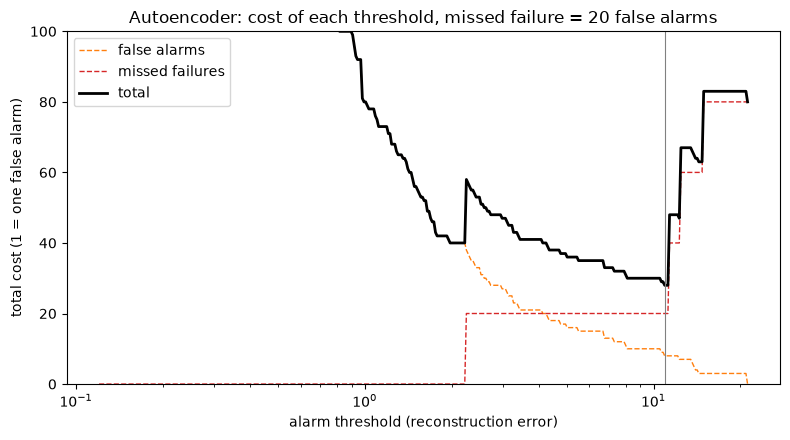

In [12]:
test = scores.loc[EVAL_FROM:]
test_days = (test.index.max() - test.index.min()) / pd.Timedelta('1D')

thresholds = np.geomspace(test.quantile(0.5), test.max(), 400)
sweep = pd.DataFrame([evaluate(test, FAILURES, t) for t in thresholds], index=thresholds)
sweep['cost'] = sweep['false_alarms'] + sweep['missed'] * COST_MISSED
best = sweep.index[sweep['cost'] == sweep['cost'].min()].min()

fig, ax = plt.subplots(figsize=(8, 4.5))
ax.plot(sweep.index, sweep['false_alarms'], color='tab:orange', lw=1, ls='--', label='false alarms')
ax.plot(sweep.index, sweep['missed'] * COST_MISSED, color='tab:red', lw=1, ls='--', label='missed failures')
ax.plot(sweep.index, sweep['cost'], color='black', lw=2, label='total')
ax.axvline(best, color='grey', lw=0.8)
ax.set_xscale('log')
ax.set_ylim(0, 100)
ax.set_xlabel('alarm threshold (reconstruction error)')
ax.set_ylabel('total cost (1 = one false alarm)')
ax.set_title(f'Autoencoder: cost of each threshold, missed failure = {COST_MISSED} false alarms')
ax.legend()
plt.tight_layout()

print(f'cheapest threshold {best:.3f}')
pd.Series(report(scores, best))

Its cost minimum is the same shelf as the KDE's at 155 in notebook 6: three
failures, F4 given up, single-figure false alarms, and no warning on anything. F3 is
then seen 10 hours after it starts. For the same reason as there, the cost minimum
is not where we would put the threshold.

In [13]:
import os

os.makedirs('../results', exist_ok=True)
scores.rename('score').rename_axis('timestamp').to_csv('../results/metropt_scores_ae.csv')
print(f'saved {len(scores):,} scores to ../results/metropt_scores_ae.csv')

saved 25,521 scores to ../results/metropt_scores_ae.csv


## What we found: the same detector, by another route

| | KDE (notebook 4) | autoencoder |
|---|---|---|
| share of F1 / F2 / F3 / F4 above 99th pct of normal | 99 / 14 / 83 / 0 % | 99 / 14 / 83 / 0 % |
| at 22 false alarms: detected | 4 (F4 by chance) | 3 |
| F3 warning | 37.8 h | 37.8 h |
| F1 warning | 0.3 h late | 37.5 h early, on one marginal alarm |
| cheapest threshold at 1 : 20 | 4 caught (F4 by chance), 22 false alarms | 3 caught, 8 false alarms, no warning |

Two quite different models (one measures density, the other how well a squeezed
copy can be rebuilt) put the same failures above the same line in the same
proportions, and their scores have a rank correlation of 0.76. The one difference,
F1's warning, rests on a single alarm just above the threshold that we cannot
tell from chance.

That is the useful result. It means the limits found in notebooks 6 and 7 are not
the KDE's: whatever a density model misses, a network that learns the relations
between the sensors misses too. F2 and F4 do not show in these seven sensors, and
F1 shows only once it has started. Together with notebook 7 (averaging does not
help), it points the same way: **the information is not in the data, so a different
model will not find it.**

So **we keep the KDE** as the main detector. It does the same job, has one
parameter instead of a network, and needs no random seed. The autoencoder adds one
thing worth keeping for the report: the per-sensor error says *why* a reading is
unusual. It shows F1 and F3 are a DV_pressure the compressor should not have, and
that much of the everyday score is oil temperature following the summer.

**Known weaknesses:**

- Training settings (30 epochs, batch 64, Adam) were not tuned. Validation loss is
  still falling slightly at epoch 30. A separate run with 100 epochs flattened out
  by epoch 50 and gave the same shares above the line and the same result at 22
  false alarms, so the short training does not change the conclusion.
- Same training period as notebook 4, so the same open question: the March
  DV_pressure spikes are taught as normal.